# EDA — Matrículas e Inscripciones (ISTS)

**Fuente:** `data/raw/matriculas/matriculas.xlsx` (hoja `estadisticas_inscrip`)

Este notebook explora el dataset de inscripciones/matrículas del Instituto Superior Tecnológico Sudamericano (ISTS), ya anonimizado por la institución (identidad y contacto fueron reemplazados por datos ficticios de prueba; el resto de los campos académicos son reales).

Objetivo: entender volumen, composición y tasas clave (matriculación, retiro) antes de construir indicadores y tableros formales.

> Parte del Observatorio Institucional de Datos Académicos — ver `PLAN-RETO-OBSERVATORIO.md` en la raíz del proyecto, Fase 6 (Análisis exploratorio de datos).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)

FILE = "../data/raw/matriculas/matriculas.xlsx"

# Cédulas y teléfonos ecuatorianos pueden empezar en "0" (provincias 01-09):
# si se dejan inferir, pandas los vuelve float y pierde ese cero. Se cargan
# como texto desde el inicio.
ID_COLS = ["NÚMERO DE DOCUMENTO", "TELÉFONO CELULAR", "TELEFONO FIJO"]
df = pd.read_excel(FILE, sheet_name="estadisticas_inscrip", dtype={c: str for c in ID_COLS})

# Varios encabezados traen espacios colgantes (p. ej. "NACIMIENTO "), invisibles
# a simple vista pero suficientes para romper un df["NACIMIENTO"].
df.columns = df.columns.str.strip()

print("Dimensiones:", df.shape)
df.head(3)

Dimensiones: (40, 34)


,FECHA INSCRIPCIÓN,TIPO DE DOCUMENTO,NÚMERO DE DOCUMENTO,NOMBRES Y APELLIDOS,ESTADO CIVIL,NACIONALIDAD,SEXO,CORREO,TELÉFONO CELULAR,TELEFONO FIJO,...,PERSONA REGISTRO INTERESADO,PERSONA CREO INSCRIPCION,PERIODO,MATRICULADO,FECHA MATRICULA,FECHA PAGO MAT.,ULTIMA MATRICULA,OPCION DE PAGO,RETIRADO,TIPO RETIRO
0,2026-06-02,CEDULA,0701695289,SANCHEZ RODRIGUEZ FERNANDO VALENTINA,SOLTERO,ECUATORIANO/ECUATORIANA,MUJER,fernando.sanchez93@hotmail.com,0935061471,073021913,...,XAVIER CORREA,PAOLA ENCALADA,PERIODO NOVIEMBRE 2026 - MARZO 2027 MACHALA,SI,2026-08-05,2026-08-05,1ER NIVEL,PLAN B,NO,NaN
1,2026-07-20,CEDULA,0702063441,PARDO SANCHEZ SCARLETT CAMILA,SOLTERO,ESPAñOL/ESPAñOLA,MUJER,scarlett.pardo59@outlook.com,0974877290,078552453,...,PAOLA ENCALADA,FREDDY SOLANO,PERIODO NOVIEMBRE 2026 - MARZO 2027 MACHALA,NO,NaT,NaT,NaN,NaN,NO,NaN
2,2026-06-10,CEDULA,0746148794,TORRES SUAREZ SCARLETT SCARLETT,CASADO,ECUATORIANO/ECUATORIANA,MUJER,scarlett.torres79@outlook.com,0936818402,070734778,...,PAOLA ENCALADA,FREDDY SOLANO,PERIODO NOVIEMBRE 2026 - MARZO 2027 MACHALA,NO,NaT,NaT,NaN,NaN,NO,NaN


## 1. Vista general y tipos de dato

40 inscripciones de un solo periodo (`PERIODO NOVIEMBRE 2026 - MARZO 2027 MACHALA`). Revisamos tipos de dato y convertimos las columnas de fecha, que Excel guarda como enteros (número de serie).

In [2]:
date_cols = ["FECHA INSCRIPCIÓN", "NACIMIENTO", "FECHA MATRICULA", "FECHA PAGO MAT."]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

df.dtypes.to_frame("dtype")

,dtype
FECHA INSCRIPCIÓN,datetime64[us]
TIPO DE DOCUMENTO,str
NÚMERO DE DOCUMENTO,str
NOMBRES Y APELLIDOS,str
ESTADO CIVIL,str
NACIONALIDAD,str
SEXO,str
CORREO,str
TELÉFONO CELULAR,str
TELEFONO FIJO,str


## 2. Valores nulos

Nota sobre privacidad: las columnas de identidad y contacto (`NÚMERO DE DOCUMENTO`, `NOMBRES Y APELLIDOS`, `CORREO`, `TELÉFONO CELULAR`, `TELEFONO FIJO`, `DIRECCIÓN`, `PROVINCIA, CANTON, PARROQUIA`, `CONTACTOS`, `PERSONA REGISTRO INTERESADO`, `PERSONA CREO INSCRIPCION`) venían **100% anonimizadas** por la institución. En esta copia de trabajo se rellenaron con datos ficticios (ver `PLAN-RETO-OBSERVATORIO.md`) solo para poder probar el pipeline completo — por eso no aparecerán como nulas abajo. **No deben usarse para identificar personas reales.**

Lo que sí es dato real faltante son los vacíos que varían fila a fila, típicamente ligados al estado de matrícula/retiro de cada estudiante.

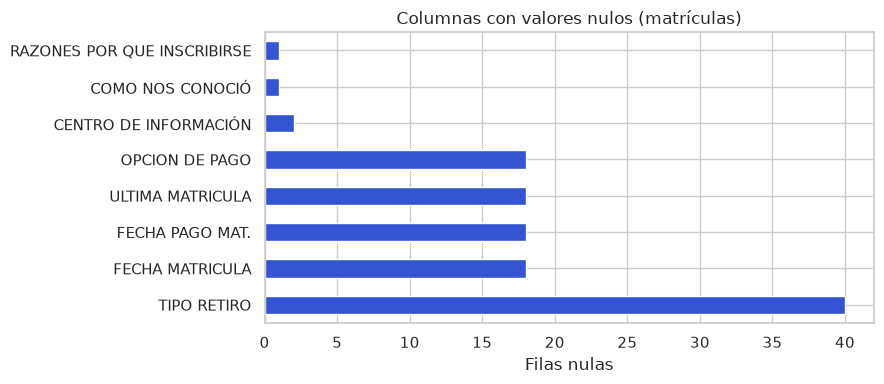

,nulos
TIPO RETIRO,40
FECHA MATRICULA,18
FECHA PAGO MAT.,18
ULTIMA MATRICULA,18
OPCION DE PAGO,18
CENTRO DE INFORMACIÓN,2
COMO NOS CONOCIÓ,1
RAZONES POR QUE INSCRIBIRSE,1


In [3]:
nulls = df.isna().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
nulls.plot(kind="barh", ax=ax, color="#3454d1")
ax.set_xlabel("Filas nulas")
ax.set_title("Columnas con valores nulos (matrículas)")
plt.tight_layout()
plt.show()

nulls.to_frame("nulos")

## 3. Composición del grupo: edad, sexo, carrera, modalidad

In [4]:
df["EDAD"].describe().to_frame("EDAD")

,EDAD
count,40.000000
mean,24.000000
std,7.404088
min,18.000000
25%,18.000000
50%,20.500000
75%,29.000000
max,44.000000


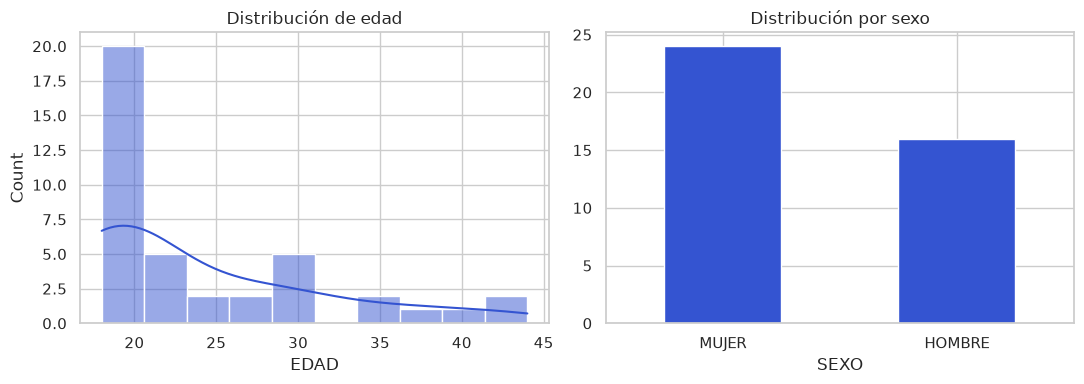

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["EDAD"], bins=10, kde=True, ax=axes[0], color="#3454d1")
axes[0].set_title("Distribución de edad")

df["SEXO"].value_counts().plot(kind="bar", ax=axes[1], color="#3454d1")
axes[1].set_title("Distribución por sexo")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

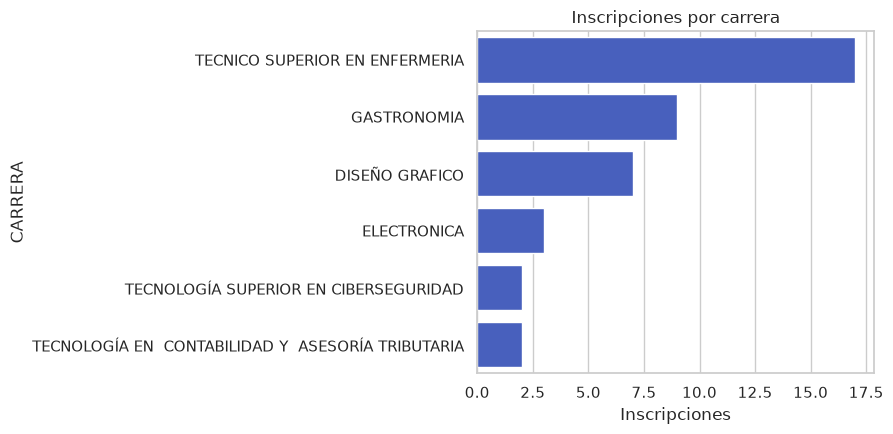

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = df["CARRERA"].value_counts().index
sns.countplot(data=df, y="CARRERA", order=order, color="#3454d1", ax=ax)
ax.set_title("Inscripciones por carrera")
ax.set_xlabel("Inscripciones")
plt.tight_layout()
plt.show()

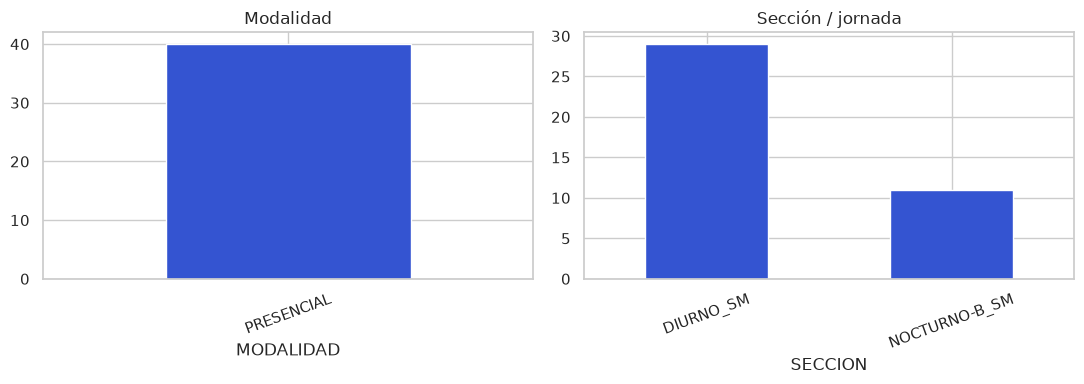

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["MODALIDAD"].value_counts().plot(kind="bar", ax=axes[0], color="#3454d1")
axes[0].set_title("Modalidad")
axes[0].tick_params(axis="x", rotation=20)

df["SECCION"].value_counts().plot(kind="bar", ax=axes[1], color="#3454d1")
axes[1].set_title("Sección / jornada")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 4. ¿Cómo nos conocieron?

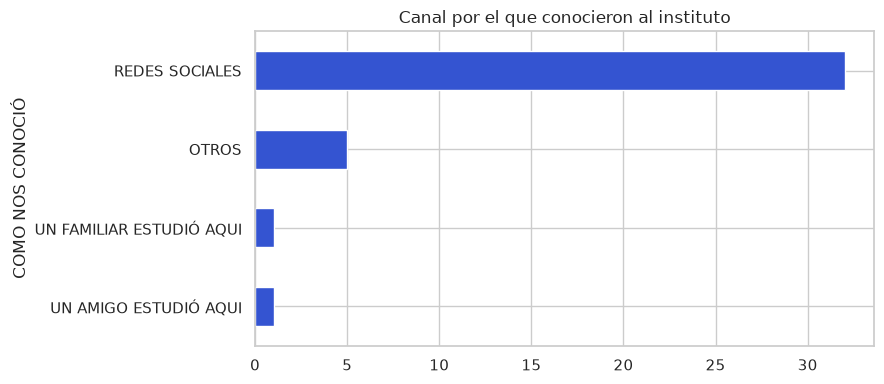

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
df["COMO NOS CONOCIÓ"].value_counts().plot(kind="barh", color="#3454d1", ax=ax)
ax.set_title("Canal por el que conocieron al instituto")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Tasas de matriculación y retiro

`MATRICULADO` indica si la inscripción se concretó en matrícula; `RETIRADO` indica si, habiéndose matriculado, el estudiante se retiró después. Son los dos indicadores de permanencia más directos de esta fuente.

Inscripciones totales:        40
Tasa de matriculación:        55.0%  (22 de 40)
Tasa de retiro (matriculados): 0.0%  (0 de 22)


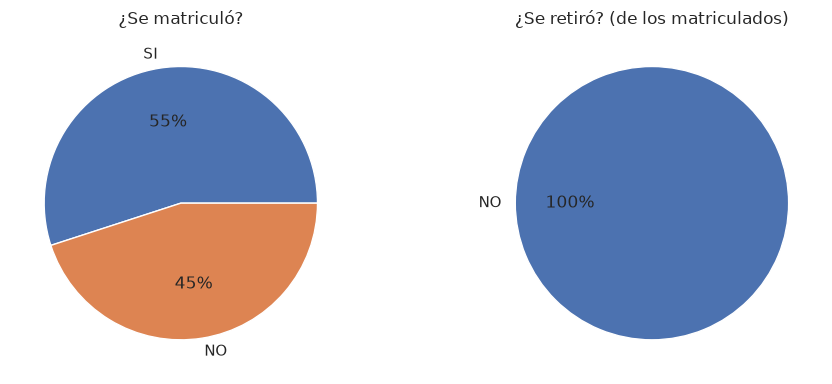

In [9]:
tasa_matricula = (df["MATRICULADO"] == "SI").mean()
matriculados = df[df["MATRICULADO"] == "SI"]
tasa_retiro = (matriculados["RETIRADO"] == "SI").mean() if len(matriculados) else float("nan")

print(f"Inscripciones totales:        {len(df)}")
print(f"Tasa de matriculación:        {tasa_matricula:.1%}  ({df['MATRICULADO'].eq('SI').sum()} de {len(df)})")
print(f"Tasa de retiro (matriculados): {tasa_retiro:.1%}  ({matriculados['RETIRADO'].eq('SI').sum()} de {len(matriculados)})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["MATRICULADO"].value_counts().plot(kind="pie", autopct="%1.0f%%", ax=axes[0], ylabel="")
axes[0].set_title("¿Se matriculó?")
matriculados["RETIRADO"].value_counts().plot(kind="pie", autopct="%1.0f%%", ax=axes[1], ylabel="")
axes[1].set_title("¿Se retiró? (de los matriculados)")
plt.tight_layout()
plt.show()

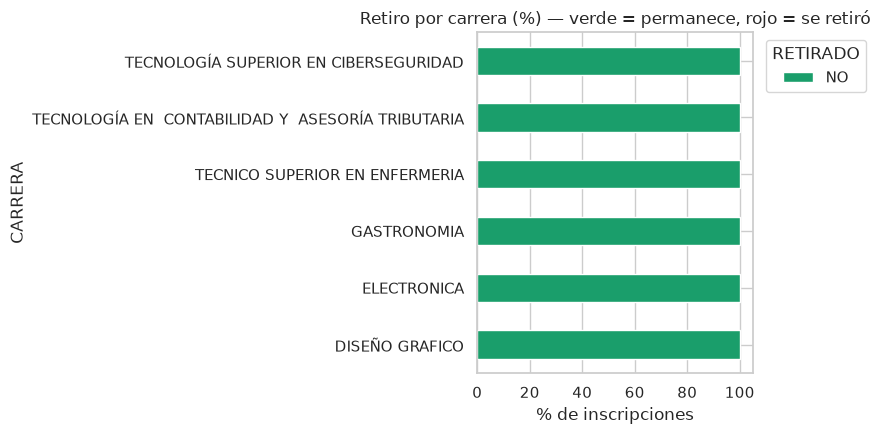

RETIRADO,NO
CARRERA,
DISEÑO GRAFICO,7
ELECTRONICA,3
GASTRONOMIA,9
TECNICO SUPERIOR EN ENFERMERIA,17
TECNOLOGÍA EN CONTABILIDAD Y ASESORÍA TRIBUTARIA,2
TECNOLOGÍA SUPERIOR EN CIBERSEGURIDAD,2


In [10]:
ct = pd.crosstab(df["CARRERA"], df["RETIRADO"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
colors = {"NO": "#1a9e6b", "SI": "#d14545"}

fig, ax = plt.subplots(figsize=(9, 4.5))
ct_pct[[c for c in ct_pct.columns if c in colors]].plot(
    kind="barh", stacked=True, ax=ax, color=[colors[c] for c in ct_pct.columns if c in colors]
)
ax.set_xlabel("% de inscripciones")
ax.set_title("Retiro por carrera (%) — verde = permanece, rojo = se retiró")
ax.legend(title="RETIRADO", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

ct

## 6. Evolución de inscripciones en el tiempo

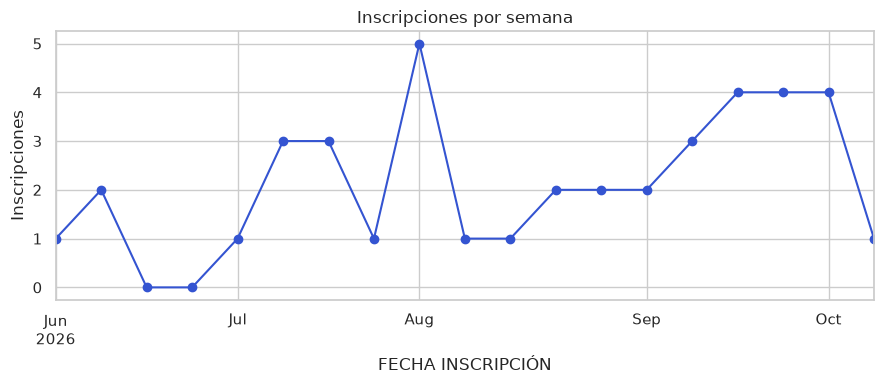

In [11]:
por_semana = df.set_index("FECHA INSCRIPCIÓN").resample("W").size()

fig, ax = plt.subplots(figsize=(9, 4))
por_semana.plot(kind="line", marker="o", ax=ax, color="#3454d1")
ax.set_ylabel("Inscripciones")
ax.set_title("Inscripciones por semana")
plt.tight_layout()
plt.show()

## 7. Hallazgos preliminares

- **Tamaño de muestra:** N = 40 inscripciones, un solo periodo (`NOVIEMBRE 2026 - MARZO 2027 MACHALA`). Cualquier tasa aquí es orientativa, no concluyente — hace falta acumular varios periodos para hablar de tendencia.
- **Matriculación:** 55% de las inscripciones (22 de 40) se concretaron en matrícula.
- **Retiro:** 0% de retiro dentro de esta fuente (0 de 22 matriculados). El archivo `retiro.xlsx` sí registra un retiro, pero corresponde a un periodo distinto y anterior (`NOVIEMBRE 2024 - MARZO 2025`) — **las dos fuentes no son comparables fila a fila para este periodo** (ver `eda_retiro.ipynb`).
- **Composición:** 60% mujeres / 40% hombres; edad mediana 20.5 años (media 24, por una cola de estudiantes de más edad, máx. 44); 100% modalidad presencial, 73% jornada diurna.
- **Carreras:** `TECNICO SUPERIOR EN ENFERMERIA` concentra el 42% de las inscripciones (17 de 40), seguida de Gastronomía (9) y Diseño Gráfico (7); Ciberseguridad, Contabilidad/Asesoría Tributaria y Electrónica tienen muy pocos casos (2-3) — insuficiente para comparar tasas entre carreras con esta muestra.
- **Captación:** 80% de los inscritos llegó por redes sociales — canal claramente dominante sobre referidos (familiar/amigo) y otros medios.

**Siguiente paso sugerido:** repetir este notebook cuando haya datos de 2-3 periodos adicionales, para poder hablar de tendencia real de matriculación/retiro y no solo de una fotografía puntual.

## 8. Exportar dataset limpio

Guardamos el DataFrame ya limpio (encabezados sin espacios, fechas tipadas, IDs como texto) como un `.xlsx` nuevo — mismo formato de archivo, listo para que otra persona del equipo lo abra en Excel o lo reutilice sin repetir la limpieza.

In [12]:
import os

OUT_DIR = "../data/clean"
os.makedirs(OUT_DIR, exist_ok=True)
OUT_FILE = os.path.join(OUT_DIR, "matriculas_limpio.xlsx")

df.to_excel(OUT_FILE, sheet_name="estadisticas_inscrip", index=False)
print(f"Guardado: {OUT_FILE}  ({df.shape[0]} filas x {df.shape[1]} columnas)")

Guardado: ../data/clean/matriculas_limpio.xlsx  (40 filas x 34 columnas)
